<sub>**The Annotated ML Handbook** · Part V: scikit-learn · by Mahir Absar Khan</sub>

# Chapter 21: Regression: predicting numbers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/21-sklearn-regression.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

Regression models predict a continuous target. This chapter compares the main families (linear models, regularised linear models, nearest neighbours, trees and ensembles) on the insurance data, explains the metrics, and shows the diagnostic plots that tell you *how* a model is wrong.

## 21.1 Set-up: one preprocessor, many models · *Beginner*

**Shared data and preprocessing**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

ins = pd.read_csv("insurance.csv")
X, y = ins.drop(columns="charges"), ins["charges"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols, cat_cols = ["age", "bmi", "children"], ["sex", "smoker", "region"]
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
])
print(X_tr.shape, X_te.shape)

(800, 6) (200, 6)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Import pandas (the table library) under the short name <code>pd</code>.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Import Matplotlib&#x27;s plotting interface under the short name <code>plt</code>.</td></tr>
<tr><td><code>from sklearn.model_selection import train_test_split</code></td><td>Import <code>train_test_split</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>from sklearn.compose import ColumnTransformer</code></td><td>Import <code>ColumnTransformer</code> from scikit-learn&#x27;s <code>compose</code> module.</td></tr>
<tr><td><code>from sklearn.pipeline import Pipeline, make_pipeline</code></td><td>Import <code>Pipeline</code> and <code>make_pipeline</code> from scikit-learn&#x27;s <code>pipeline</code> module.</td></tr>
<tr><td><code>from sklearn.preprocessing import StandardScaler, OneHotEncoder</code></td><td>Import <code>StandardScaler</code> and <code>OneHotEncoder</code> from scikit-learn&#x27;s <code>preprocessing</code> module.</td></tr>
<tr><td><code>from sklearn.impute import SimpleImputer</code></td><td>Import <code>SimpleImputer</code> from scikit-learn&#x27;s <code>impute</code> module.</td></tr>
<tr><td><code>ins = pd.read_csv(&quot;insurance.csv&quot;)</code></td><td>Load the practice dataset.</td></tr>
<tr><td><code>X, y = ins.drop(columns=&quot;charges&quot;), ins[&quot;charges&quot;]</code></td><td>Features and target.</td></tr>
<tr><td><code>X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)</code></td><td>80/20 split.</td></tr>
<tr><td><code>num_cols, cat_cols = [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;], [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;]</code></td><td>Column groups.</td></tr>
<tr><td><code>pre = ColumnTransformer([</code></td><td>Preprocessing for the two column groups:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;(&quot;num&quot;, make_pipeline(SimpleImputer(strategy=&quot;median&quot;), StandardScaler()), num_cols),</code></td><td>Numeric: impute the median, then standardise.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;(&quot;cat&quot;, OneHotEncoder(handle_unknown=&quot;ignore&quot;, drop=&quot;if_binary&quot;), cat_cols),</code></td><td>Categorical: one-hot encode.</td></tr>
<tr><td><code>])</code></td><td>Close the list and the call or tuple opened above.</td></tr>
<tr><td><code>print(X_tr.shape, X_te.shape)</code></td><td>(800, 6) and (200, 6).</td></tr>
</table>
</details>

## 21.2 Regression metrics · *Beginner*

> **📖 Definitions**
>
> **MAE (mean absolute error)**: the average size of prediction errors, in the target's units.
>
> **RMSE (root mean squared error)**: the square root of the average squared error. It penalises large errors more than MAE.
>
> **R² (coefficient of determination)**: the share of the target's variance explained by the model: 1 is perfect, 0 is no better than predicting the mean, negative is worse.


| Metric | Formula (in words) | Units | Read it as |
|---|---|---|---|
| **MAE** | mean of \|error\| | target units | "on average we are off by this much"; robust to outliers |
| **RMSE** | square root of mean squared error | target units | penalises large errors more than MAE |
| **R²** | 1 − SSE / total variance | none, at most 1 | share of variance explained; 0 = as good as predicting the mean, negative = worse |
| **MAPE** | mean of \|error\| / \|true\| | % | relative error; unstable when true values are near 0 |

**A helper to evaluate any regressor**

In [3]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

def evaluate(model, name):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {"model": name,
            "MAE": mean_absolute_error(y_te, pred),
            "RMSE": root_mean_squared_error(y_te, pred),
            "R2": r2_score(y_te, pred),
            "MAPE%": 100 * mean_absolute_percentage_error(y_te, pred)}

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error</code></td><td>Import <code>mean_absolute_error</code>, <code>root_mean_squared_error</code>, <code>r2_score</code> and <code>mean_absolute_percentage_error</code> from scikit-learn&#x27;s <code>metrics</code> module.</td></tr>
<tr><td><code>def evaluate(model, name):</code></td><td>Define a function <code>evaluate</code> that takes <code>model</code> and <code>name</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;model.fit(X_tr, y_tr)</code></td><td>Fit on training data.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;pred = model.predict(X_te)</code></td><td>Predict the held-out test set.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return {&quot;model&quot;: name,</code></td><td>Send <code>{&quot;model&quot;: name,</code> back to the caller.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;MAE&quot;: mean_absolute_error(y_te, pred),</code></td><td>Average absolute error.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;RMSE&quot;: root_mean_squared_error(y_te, pred),</code></td><td>scikit-learn &gt;= 1.4 provides RMSE directly.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;R2&quot;: r2_score(y_te, pred),</code></td><td>Share of variance explained.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;MAPE%&quot;: 100 * mean_absolute_percentage_error(y_te, pred)}</code></td><td>Average percentage error.</td></tr>
</table>
</details>

## 21.3 Linear models · *Beginner*

> **📖 Definitions**
>
> **Linear regression**: a model predicting the target as a weighted sum of the features plus an intercept, fitted by least squares.
>
> **Coefficient**: the weight a linear model gives a feature: the change in prediction per unit change in that feature, holding the others fixed.
>
> **Regularisation**: adding a penalty on model complexity (such as large coefficients) to reduce overfitting. **L2 (Ridge)** shrinks all coefficients; **L1 (Lasso)** can set some to exactly zero.


Linear regression models the target as a weighted sum of features: ŷ = b + w₁x₁ + … + wₚxₚ. **Regularisation** adds a penalty on the size of the weights to reduce overfitting:

- **Ridge (L2)** shrinks all coefficients toward zero; good when many features each matter a little.
- **Lasso (L1)** can set coefficients exactly to zero, performing feature selection.
- **ElasticNet** mixes both. `alpha` sets the penalty strength (higher = simpler model).

**Ordinary, Ridge, Lasso and ElasticNet**

In [4]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor

results = [
    evaluate(Pipeline([("pre", pre), ("m", DummyRegressor())]), "Mean baseline"),
    evaluate(Pipeline([("pre", pre), ("m", LinearRegression())]), "Linear"),
    evaluate(Pipeline([("pre", pre), ("m", Ridge(alpha=1.0))]), "Ridge"),
    evaluate(Pipeline([("pre", pre), ("m", Lasso(alpha=10.0))]), "Lasso"),
    evaluate(Pipeline([("pre", pre), ("m", ElasticNet(alpha=0.1, l1_ratio=0.5))]), "ElasticNet"),
]
print(pd.DataFrame(results).round(3).to_string(index=False))

        model      MAE     RMSE     R2  MAPE%
Mean baseline 7296.699 9809.561 -0.011 35.173
       Linear 1821.972 2452.403  0.937  9.311
        Ridge 1813.913 2443.709  0.937  9.314
        Lasso 1822.076 2451.496  0.937  9.336
   ElasticNet 2562.295 3151.501  0.896 12.520


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet</code></td><td>Import <code>LinearRegression</code>, <code>Ridge</code>, <code>Lasso</code> and <code>ElasticNet</code> from scikit-learn&#x27;s <code>linear_model</code> module.</td></tr>
<tr><td><code>from sklearn.dummy import DummyRegressor</code></td><td>Import <code>DummyRegressor</code> from scikit-learn&#x27;s <code>dummy</code> module.</td></tr>
<tr><td><code>results = [</code></td><td>Collect one result dict per model.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, DummyRegressor())]), &quot;Mean baseline&quot;),</code></td><td>Always predicts the training mean.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, LinearRegression())]), &quot;Linear&quot;),</code></td><td>Ordinary least squares.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, Ridge(alpha=1.0))]), &quot;Ridge&quot;),</code></td><td>L2 penalty.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, Lasso(alpha=10.0))]), &quot;Lasso&quot;),</code></td><td>L1 penalty.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, ElasticNet(alpha=0.1, l1_ratio=0.5))]), &quot;ElasticNet&quot;),</code></td><td>Half L1, half L2.</td></tr>
<tr><td><code>]</code></td><td>Close the list opened above.</td></tr>
<tr><td><code>print(pd.DataFrame(results).round(3).to_string(index=False))</code></td><td>to_string(index=False) prints a clean table.</td></tr>
</table>
</details>

### 21.3.1 Reading coefficients · *Intermediate*

**Which features push predictions up or down?**

In [5]:
lin = Pipeline([("pre", pre), ("m", LinearRegression())]).fit(X_tr, y_tr)
coefs = pd.Series(lin.named_steps["m"].coef_,
                  index=lin.named_steps["pre"].get_feature_names_out()).sort_values()
print(coefs.round(0))
print("intercept:", round(lin.named_steps["m"].intercept_, 0))

cat__region_southeast     -220.0
cat__region_northeast      -95.0
cat__sex_male              -58.0
cat__region_northwest       19.0
cat__region_southwest      295.0
num__children              529.0
num__bmi                   883.0
num__age                  3446.0
cat__smoker_yes          23013.0
dtype: float64
intercept: 17126.0


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>lin = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, LinearRegression())]).fit(X_tr, y_tr)</code></td><td>Fit a linear model to inspect.</td></tr>
<tr><td><code>coefs = pd.Series(lin.named_steps[&quot;m&quot;].coef_,</code></td><td>One coefficient per transformed feature...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;index=lin.named_steps[&quot;pre&quot;].get_feature_names_out()).sort_values()</code></td><td>Pair each coefficient with its feature name.</td></tr>
<tr><td><code>print(coefs.round(0))</code></td><td>Sorted from most negative to most positive.</td></tr>
<tr><td><code>print(&quot;intercept:&quot;, round(lin.named_steps[&quot;m&quot;].intercept_, 0))</code></td><td>Predicted charges when every feature is 0 (i.e. at average numeric values).</td></tr>
</table>
</details>

Because numeric features were standardised, each numeric coefficient means "change in charges for a one-standard-deviation increase". The `smoker_yes` coefficient is the estimated extra cost of smoking, holding the other features fixed.

> **⚠️ Pitfall** · **Coefficients are not causal effects**
>
> Regression coefficients describe associations in *this* data, conditional on the other features in the model. They can change sign when correlated features are added or removed. For inference (confidence intervals, p-values) use `statsmodels`; scikit-learn focuses on prediction.

### 21.3.2 The regularisation path · *Intermediate*

**Lasso drives coefficients to zero as alpha grows**

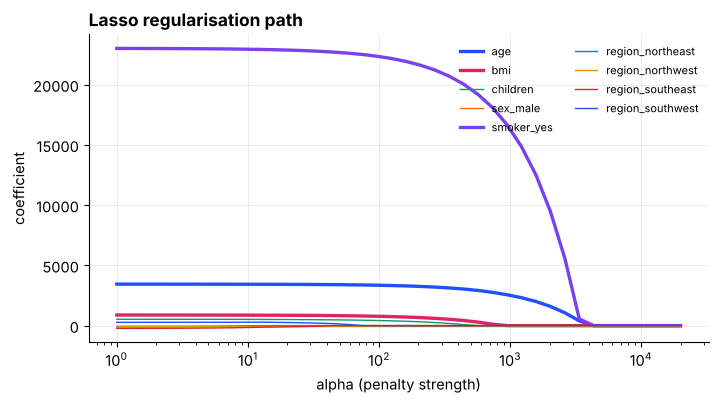

In [6]:
alphas = np.logspace(0, 4.3, 40)
Xt_tr = pre.fit_transform(X_tr)
names = pre.get_feature_names_out()
paths = np.array([Lasso(alpha=a, max_iter=20000).fit(Xt_tr, y_tr).coef_ for a in alphas])
fig, ax = plt.subplots(figsize=(8, 4))
for j, name in enumerate(names):
    lw = 2.4 if name in ("cat__smoker_yes", "num__age", "num__bmi") else 1
    ax.plot(alphas, paths[:, j], lw=lw, label=name.split("__")[1])
ax.set(xscale="log", xlabel="alpha (penalty strength)", ylabel="coefficient", title="Lasso regularisation path")
ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>alphas = np.logspace(0, 4.3, 40)</code></td><td>40 values from 1 to ~20,000 on a log scale.</td></tr>
<tr><td><code>Xt_tr = pre.fit_transform(X_tr)</code></td><td>Preprocess once, outside a pipeline, for this plot.</td></tr>
<tr><td><code>names = pre.get_feature_names_out()</code></td><td>Feature names after preprocessing.</td></tr>
<tr><td><code>paths = np.array([Lasso(alpha=a, max_iter=20000).fit(Xt_tr, y_tr).coef_ for a in alphas])</code></td><td>One row of coefficients per alpha.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(8, 4))</code></td><td>One panel.</td></tr>
<tr><td><code>for j, name in enumerate(names):</code></td><td>Loop over <code>enumerate(names)</code>, naming each item <code>j, name</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;lw = 2.4 if name in (&quot;cat__smoker_yes&quot;, &quot;num__age&quot;, &quot;num__bmi&quot;) else 1</code></td><td>Thicker lines for the key features.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.plot(alphas, paths[:, j], lw=lw, label=name.split(&quot;__&quot;)[1])</code></td><td>One coefficient&#x27;s path across alphas.</td></tr>
<tr><td><code>ax.set(xscale=&quot;log&quot;, xlabel=&quot;alpha (penalty strength)&quot;, ylabel=&quot;coefficient&quot;, title=&quot;Lasso regularisation path&quot;)</code></td><td>Log x-axis, labels and title.</td></tr>
<tr><td><code>ax.legend(fontsize=8, ncol=2, loc=&quot;upper right&quot;)</code></td><td>Compact two-column legend.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 21.4 Non-linear models · *Intermediate*

**kNN, decision tree, random forest, gradient boosting**

In [7]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

results += [
    evaluate(Pipeline([("pre", pre), ("m", KNeighborsRegressor(n_neighbors=10))]), "kNN (k=10)"),
    evaluate(Pipeline([("pre", pre), ("m", SVR(C=20000, epsilon=500))]), "SVR (RBF)"),
    evaluate(Pipeline([("pre", pre), ("m", DecisionTreeRegressor(max_depth=5, random_state=0))]), "Tree (depth 5)"),
    evaluate(Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))]), "Random forest"),
    evaluate(Pipeline([("pre", pre), ("m", GradientBoostingRegressor(random_state=0))]), "Gradient boosting"),
    evaluate(Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(random_state=0))]), "HistGradientBoosting"),
]
table = pd.DataFrame(results).sort_values("RMSE").round(3)
print(table.to_string(index=False))

               model      MAE     RMSE     R2  MAPE%
               Ridge 1813.913 2443.709  0.937  9.314
               Lasso 1822.076 2451.496  0.937  9.336
              Linear 1821.972 2452.403  0.937  9.311
   Gradient boosting 1851.234 2515.920  0.933  9.427
       Random forest 1894.608 2573.662  0.930  9.708
HistGradientBoosting 1949.798 2606.751  0.929  9.927
           SVR (RBF) 1959.467 2711.818  0.923  9.916
      Tree (depth 5) 2062.774 2768.292  0.919 10.708
          ElasticNet 2562.295 3151.501  0.896 12.520
          kNN (k=10) 4227.245 6325.007  0.580 17.099
       Mean baseline 7296.699 9809.561 -0.011 35.173


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.neighbors import KNeighborsRegressor</code></td><td>Import <code>KNeighborsRegressor</code> from scikit-learn&#x27;s <code>neighbors</code> module.</td></tr>
<tr><td><code>from sklearn.tree import DecisionTreeRegressor</code></td><td>Import <code>DecisionTreeRegressor</code> from scikit-learn&#x27;s <code>tree</code> module.</td></tr>
<tr><td><code>from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor</code></td><td>Import <code>RandomForestRegressor</code>, <code>HistGradientBoostingRegressor</code> and <code>GradientBoostingRegressor</code> from scikit-learn&#x27;s <code>ensemble</code> module.</td></tr>
<tr><td><code>from sklearn.svm import SVR</code></td><td>Import <code>SVR</code> from scikit-learn&#x27;s <code>svm</code> module.</td></tr>
<tr><td><code>results += [</code></td><td>Append more results to the list.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, KNeighborsRegressor(n_neighbors=10))]), &quot;kNN (k=10)&quot;),</code></td><td>Average of the 10 nearest customers.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, SVR(C=20000, epsilon=500))]), &quot;SVR (RBF)&quot;),</code></td><td>Support vector regression; C and epsilon set for this target&#x27;s scale.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, DecisionTreeRegressor(max_depth=5, random_state=0))]), &quot;Tree (depth 5)&quot;),</code></td><td>One tree, at most 5 levels deep.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))]), &quot;Random forest&quot;),</code></td><td>300 trees, each leaf with at least 3 samples.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, GradientBoostingRegressor(random_state=0))]), &quot;Gradient boosting&quot;),</code></td><td>Classic gradient boosting.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;evaluate(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, HistGradientBoostingRegressor(random_state=0))]), &quot;HistGradientBoosting&quot;),</code></td><td>Fast histogram-based boosting.</td></tr>
<tr><td><code>]</code></td><td>Close the list opened above.</td></tr>
<tr><td><code>table = pd.DataFrame(results).sort_values(&quot;RMSE&quot;).round(3)</code></td><td>Results as a table, best first.</td></tr>
<tr><td><code>print(table.to_string(index=False))</code></td><td>Print without the row index.</td></tr>
</table>
</details>

**Compare models visually**

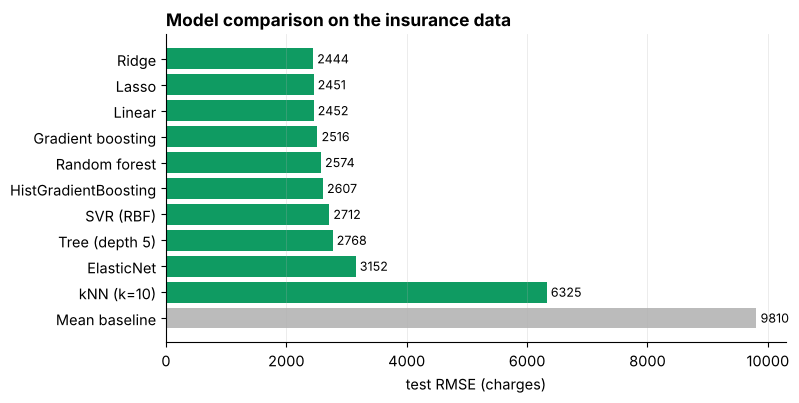

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
t = table.sort_values("RMSE", ascending=False)
colors = ["#bbb" if m == "Mean baseline" else "#0f9b62" for m in t["model"]]
bars = ax.barh(t["model"], t["RMSE"], color=colors)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.set(xlabel="test RMSE (charges)", title="Model comparison on the insurance data")
ax.grid(axis="y", visible=False)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(8, 4))</code></td><td>One panel.</td></tr>
<tr><td><code>t = table.sort_values(&quot;RMSE&quot;, ascending=False)</code></td><td>Worst first, so the best bar ends up at the top.</td></tr>
<tr><td><code>colors = [&quot;#bbb&quot; if m == &quot;Mean baseline&quot; else &quot;#0f9b62&quot; for m in t[&quot;model&quot;]]</code></td><td>Grey for the baseline, green for real models.</td></tr>
<tr><td><code>bars = ax.barh(t[&quot;model&quot;], t[&quot;RMSE&quot;], color=colors)</code></td><td>Horizontal bars.</td></tr>
<tr><td><code>ax.bar_label(bars, fmt=&quot;%.0f&quot;, padding=3, fontsize=9)</code></td><td>Write each RMSE at the end of its bar.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;test RMSE (charges)&quot;, title=&quot;Model comparison on the insurance data&quot;)</code></td><td>Labels.</td></tr>
<tr><td><code>ax.grid(axis=&quot;y&quot;, visible=False)</code></td><td>Keep only vertical grid lines.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

> **🔑 Key idea** · **Simple models first**
>
> Why do linear models win here? The relationship in this data is almost linear: charges rise steadily with age and jump by a fixed amount for smokers. Flexible models have nothing extra to discover, and they pay for their flexibility with a little extra variance. On real data with interactions and thresholds the ranking often flips. You only find out by trying a baseline, a linear model and an ensemble, in that order. Note also how badly kNN does: with one-hot columns and few samples, "nearest neighbours" are not very near.

### 21.4.1 How trees and ensembles work · *Intermediate*

> **📖 Definitions**
>
> **Decision tree**: a model that makes predictions by asking a sequence of yes/no questions about the features, ending in a leaf with a prediction.
>
> **Ensemble**: a model that combines many models' predictions, usually to improve accuracy and stability.
>
> **Random forest**: an ensemble of decision trees, each trained on a bootstrap sample with random subsets of features, whose predictions are averaged.
>
> **Gradient boosting**: an ensemble that adds shallow trees one at a time, each correcting the errors of the previous ones.


- A **decision tree** splits the data with yes/no questions ("smoker?", "age < 43?") to make groups with similar targets. It is interpretable but overfits when deep.
- A **random forest** averages hundreds of deep trees, each trained on a bootstrap sample with random feature subsets. Averaging cancels out much of the overfitting. It is robust and needs little tuning.
- **Gradient boosting** builds shallow trees *sequentially*, each one correcting the errors of the ensemble so far. It is often the most accurate for tabular data, but more sensitive to hyperparameters (`learning_rate`, `max_iter`/`n_estimators`, `max_depth`). `HistGradientBoosting*` is scikit-learn's fast implementation for larger datasets, with native missing-value support. XGBoost, LightGBM and CatBoost are popular external libraries in the same family.

**Peek inside a shallow tree**

In [9]:
from sklearn.tree import export_text
tree = Pipeline([("pre", pre), ("m", DecisionTreeRegressor(max_depth=2, random_state=0))]).fit(X_tr, y_tr)
print(export_text(tree.named_steps["m"], feature_names=list(pre.get_feature_names_out())))

|--- cat__smoker_yes <= 0.50
|   |--- num__age <= -0.14
|   |   |--- value: [13949.46]
|   |--- num__age >  -0.14
|   |   |--- value: [19912.88]
|--- cat__smoker_yes >  0.50
|   |--- num__age <= -0.28
|   |   |--- value: [36483.03]
|   |--- num__age >  -0.28
|   |   |--- value: [42618.71]



<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.tree import export_text</code></td><td>Import <code>export_text</code> from scikit-learn&#x27;s <code>tree</code> module.</td></tr>
<tr><td><code>tree = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, DecisionTreeRegressor(max_depth=2, random_state=0))]).fit(X_tr, y_tr)</code></td><td>A tiny tree that is easy to read.</td></tr>
<tr><td><code>print(export_text(tree.named_steps[&quot;m&quot;], feature_names=list(pre.get_feature_names_out())))</code></td><td>The learned if/else rules.</td></tr>
</table>
</details>

## 21.5 Diagnostic plots: how is the model wrong? · *Intermediate*

> **📖 Definitions**
>
> **Residual**: the difference between an observed value and the model's prediction (actual − predicted).

**Predicted vs actual, and residuals**

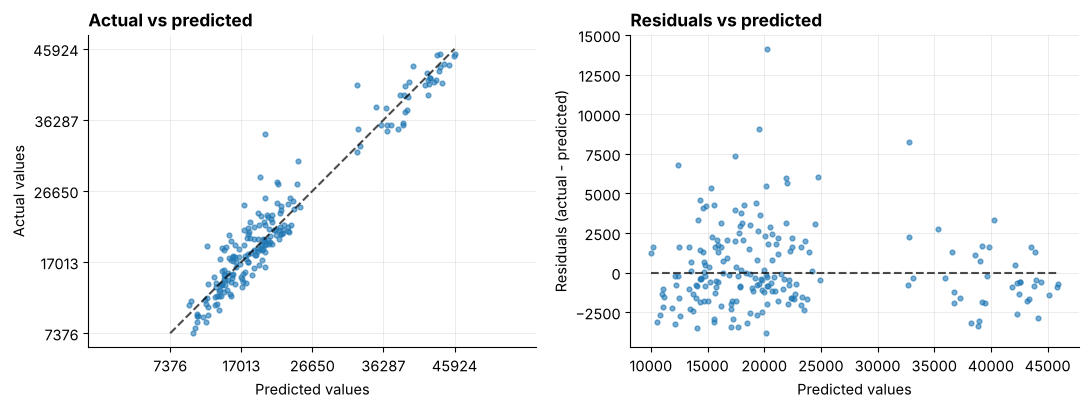

In [10]:
from sklearn.metrics import PredictionErrorDisplay

rf = Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))]).fit(X_tr, y_tr)
pred = rf.predict(X_te)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
PredictionErrorDisplay.from_predictions(y_te, pred, kind="actual_vs_predicted", ax=axes[0],
                                        scatter_kwargs={"s": 12, "alpha": 0.6})
axes[0].set_title("Actual vs predicted")
PredictionErrorDisplay.from_predictions(y_te, pred, kind="residual_vs_predicted", ax=axes[1],
                                        scatter_kwargs={"s": 12, "alpha": 0.6})
axes[1].set_title("Residuals vs predicted")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.metrics import PredictionErrorDisplay</code></td><td>Import <code>PredictionErrorDisplay</code> from scikit-learn&#x27;s <code>metrics</code> module.</td></tr>
<tr><td><code>rf = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1))]).fit(X_tr, y_tr)</code></td><td>Refit the random forest.</td></tr>
<tr><td><code>pred = rf.predict(X_te)</code></td><td>Diagnose the random forest (try it with the linear model too).</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))</code></td><td>Two panels.</td></tr>
<tr><td><code>PredictionErrorDisplay.from_predictions(y_te, pred, kind=&quot;actual_vs_predicted&quot;, ax=axes[0],</code></td><td>Panel 1: actual vs predicted...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scatter_kwargs={&quot;s&quot;: 12, &quot;alpha&quot;: 0.6})</code></td><td>scikit-learn&#x27;s built-in display class.</td></tr>
<tr><td><code>axes[0].set_title(&quot;Actual vs predicted&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>PredictionErrorDisplay.from_predictions(y_te, pred, kind=&quot;residual_vs_predicted&quot;, ax=axes[1],</code></td><td>Panel 2: residual (actual - predicted) vs predicted...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scatter_kwargs={&quot;s&quot;: 12, &quot;alpha&quot;: 0.6})</code></td><td>...small, semi-transparent points.</td></tr>
<tr><td><code>axes[1].set_title(&quot;Residuals vs predicted&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

> **💡 Tip** · **Skewed targets**
>
> Costs, incomes and counts are often right-skewed. Modelling `log(y)` can help linear models. In scikit-learn use `TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)`, so predictions and metrics come back in original units automatically.

## 21.6 Quantifying uncertainty in a test score · *Advanced*

> **📖 Definitions**
>
> **Bootstrap**: estimating the uncertainty of a statistic by recomputing it on many random resamples (drawn with replacement) of the data.
>
> **Confidence interval (CI)**: a range that would contain the true value of a quantity in a stated share (often 95%) of repeated experiments.


A single test RMSE is an estimate with sampling error. A **bootstrap** over test samples gives a confidence interval.

**Bootstrap 95% confidence interval for test RMSE**

In [11]:
rng = np.random.default_rng(0)
y_true_arr, pred_arr = y_te.to_numpy(), pred
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_true_arr), len(y_true_arr))
    boot.append(root_mean_squared_error(y_true_arr[idx], pred_arr[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"RMSE = {root_mean_squared_error(y_true_arr, pred_arr):.0f}  (95% CI {lo:.0f} to {hi:.0f})")

RMSE = 2574  (95% CI 2159 to 3032)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Seeded generator for resampling.</td></tr>
<tr><td><code>y_true_arr, pred_arr = y_te.to_numpy(), pred</code></td><td>Plain arrays for fast indexing.</td></tr>
<tr><td><code>boot = []</code></td><td>Will hold 2000 bootstrap RMSEs.</td></tr>
<tr><td><code>for _ in range(2000):</code></td><td>Loop over <code>range(2000)</code>, naming each item <code>_</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;idx = rng.integers(0, len(y_true_arr), len(y_true_arr))</code></td><td>Resample test rows WITH replacement.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;boot.append(root_mean_squared_error(y_true_arr[idx], pred_arr[idx]))</code></td><td>RMSE on this resample.</td></tr>
<tr><td><code>lo, hi = np.percentile(boot, [2.5, 97.5])</code></td><td>The middle 95% of bootstrap RMSEs.</td></tr>
<tr><td><code>print(f&quot;RMSE = {root_mean_squared_error(y_true_arr, pred_arr):.0f}  (95% CI {lo:.0f} to {hi:.0f})&quot;)</code></td><td>The point estimate with its interval.</td></tr>
</table>
</details>

> **🔬 Research practice** · **Report intervals, not just point estimates**
>
> "RMSE 2,574 (95% CI 2,159–3,032)" tells readers how much to trust the number, and whether two models' scores really differ. [Chapter 30](../part-7-ml-for-research/30-research-choosing.ipynb) covers comparing models rigorously.

> **✍️ Try it yourself**
>
> 1. Wrap the Ridge pipeline in `TransformedTargetRegressor` with a log transform and compare test RMSE.
> 2. Add an interaction feature `smoker × bmi` (hint: `PolynomialFeatures(interaction_only=True)` or a custom column) to the linear model. Does it close the gap to the random forest?
> 3. Plot test RMSE against `max_depth` from 1 to 15 for a single decision tree. Where does overfitting start?
>
> *Worked solutions:* [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 21*.

---

⬅️ [Chapter 20: Preprocessing, feature engineering and pipelines](20-sklearn-preprocessing.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 22: Classification: predicting categories](22-sklearn-classification.ipynb) ➡️